# RQ1: How do developers’ perceptions regarding frequency of use, effectiveness, ease of use, and essentiality differ across software security practices?

Outputs (`results/RQ1/`):

- `comparison_categories.xlsx`: perceived level of each attribute for each practice: sum of the valid answers divided by the number of valid answers times the maximum of the scale ('Não Aplicável' (Not Applicable) answers are excluded).
- `correlations.xlsx`: Spearman correlations between the attributes for each practice, using only the participants who rated both attributes ('Não Aplicável' excluded), with the Holm-Bonferroni adjusted p-values (one family of 16 tests, one per practice, for each pair of attributes).

The LaTeX tables are generated from these spreadsheets by `scripts/generate_latex_tables.py`.

## Pre-processing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_rows', None)
from pathlib import Path

In [2]:
data_path = Path('data')
df_o = pd.read_excel(data_path / 'survey_all_responses_ptbr.xlsx')

df = df_o[:]

df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace('\n', '', regex=True)

print(len(df))

#print(df.columns.tolist())

95


In [3]:
print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())


df = df[~(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'] == 'Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software')]

print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())
print(df.shape)

<StringArray>
[                            'Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software',
 'Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.',
                                           'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
Length: 3, dtype: str
<StringArray>
['Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.', 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
Length: 2, dtype: str
(83, 102)


In [4]:
df[df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna()]

,Carimbo de data/hora,"Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.",Qual é a sua idade?,Em qual estado do Brasil você mora atualmente?,Qual é o seu gênero?,Qual é o seu nível de educação formal concluída?,Qual seu modelo de trabalho?,Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?,"Por favor, indique a senioridade da posição que ocupa.",Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?,...,Em quais fases do ciclo de desenvolvimento de software você costuma utilizar as ferramentas de segurança automatizadas selecionadas na pergunta anterior? (Selecione todas as opções que se aplicam),Quais recomendações você daria para um desenvolvedor sobre a adoção de ferramentas de segurança para seus projetos?,Quais são os principais desafios que você enfrenta ao automatizar ferramentas de segurança? (Selecione todas as opções que se aplicam),Quais melhorias você gostaria de ver nas ferramentas de segurança automatizadas que utiliza atualmente? (Selecione todas as opções que se aplicam),"Caso você queira receber os resultados desse estudo e participar de uma futura entrevista sobre Práticas de Segurança de Software, por favor, informe seu Email.","Quais são as razões pelas quais você opta por não utilizar ferramentas automatizadas de segurança de software? Por favor, descreva brevemente sobre.",Você considera utilizar ferramentas automatizadas de segurança de software em seus projetos no futuro?,"Se você respondeu ""Sim"" ou ""Talvez"" à pergunta anterior, por favor, indique quais ferramentas utilizaria. Marque ""Nenhuma"" se respondeu ""Não"".","Caso você queira receber os resultados desse estudo e participar de uma futura entrevista sobre Práticas de Segurança de Software, por favor, informe seu Email..1",Marque a imagem em que aparece um filhote de cachorro:


In [5]:
print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna().sum())

df = df.drop(df[df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna()].index, axis=0)

print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna().sum())

0
0


In [6]:
df['Qual é o seu nível de educação formal concluída?'].unique()

<StringArray>
[              'Mestrado', 'Estudante de Doutorado',        'Ensino Superior',
              'Doutorado',         'Especialização',           'Ensino Médio',
  'Estudante de Mestrado']
Length: 7, dtype: str

In [7]:
df.isna().sum()

Carimbo de data/hora                                                                                                                                                                                                                                                                                                                                                                                                                                            0
Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.     0
Qual é a sua idade?                                                                                 

In [8]:
df.shape

(83, 102)

Weight

In [9]:
practices = ['[Revisão de Código]',
            '[Modelagem de Ameaças]',
            '[Identificação de Casos de Abuso/Mau Uso]',
            '[Análise de Riscos Arquiteturais]',
            '[Testes de Penetração]',
            '[Gerenciamento de Riscos]',
            '[Gerenciamento de Vulnerabilidades]',
            '[Testes de Segurança Manuais/Automatizados]',
            '[Execução de Testes Fuzz]',
            '[Engenharia de Requisitos de Segurança]',
            '[Codificação Segura]',
            '[Resposta Emergencial ao Código]',
            '[Configurações e Gerenciamento de Segurança]',
            '[Monitoramento de Eventos de Segurança]',
            '[Auditorias de Segurança Externas]',
            '[Segurança da Cadeia de Suprimentos de Software]']

# English names of the practices, in the same order (used in the outputs)
practices_en = ['Code Review',
                'Threat Modeling',
                'Identifying Abuse/Misuse Cases',
                'Architectural Risk Analysis',
                'Penetration Testing',
                'Risk Management',
                'Vulnerability Management',
                'Manual/Automated Security Testing',
                'Performing Fuzz Testing',
                'Security Requirements Engineering',
                'Secure Coding',
                'Emergency Codebase Response',
                'Security Configurations & Management',
                'Monitoring for Security Events',
                'Undergoing External Security Audits',
                'Software Supply Chain Security']

In [10]:
frequency_cols = [ 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Revisão de Código]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Modelagem de Ameaças]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Identificação de Casos de Abuso/Mau Uso]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Análise de Riscos Arquiteturais]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Testes de Penetração]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Gerenciamento de Riscos]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Gerenciamento de Vulnerabilidades]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Testes de Segurança Manuais/Automatizados]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Execução de Testes Fuzz]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Engenharia de Requisitos de Segurança]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Codificação Segura]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Resposta Emergencial ao Código]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Configurações e Gerenciamento de Segurança]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Monitoramento de Eventos de Segurança]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Auditorias de Segurança Externas]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Segurança da Cadeia de Suprimentos de Software]'
]


In [11]:
ease_of_use_cols = ['Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Revisão de Código]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Modelagem de Ameaças]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Identificação de Casos de Abuso/Mau Uso]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Análise de Riscos Arquiteturais]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Testes de Penetração]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Gerenciamento de Riscos]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Gerenciamento de Vulnerabilidades]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Testes de Segurança Manuais/Automatizados]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Execução de Testes Fuzz]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Engenharia de Requisitos de Segurança]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Codificação Segura]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Resposta Emergencial ao Código]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Configurações e Gerenciamento de Segurança]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Monitoramento de Eventos de Segurança]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Auditorias de Segurança Externas]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Segurança da Cadeia de Suprimentos de Software]'
]


In [12]:
effectiveness_cols = ['Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Revisão de Código]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Modelagem de Ameaças]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Identificação de Casos de Abuso/Mau Uso]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Análise de Riscos Arquiteturais]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Testes de Penetração]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Gerenciamento de Riscos]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Gerenciamento de Vulnerabilidades]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Testes de Segurança Manuais/Automatizados]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Execução de Testes Fuzz]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Engenharia de Requisitos de Segurança]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Codificação Segura]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Resposta Emergencial ao Código]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Configurações e Gerenciamento de Segurança]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Monitoramento de Eventos de Segurança]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Auditorias de Segurança Externas]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Segurança da Cadeia de Suprimentos de Software]'
]

In [13]:
essentiality_cols = ['Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Revisão de Código]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Modelagem de Ameaças]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Identificação de Casos de Abuso/Mau Uso]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Análise de Riscos Arquiteturais]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Testes de Penetração]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Gerenciamento de Riscos]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Gerenciamento de Vulnerabilidades]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Testes de Segurança Manuais/Automatizados]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Execução de Testes Fuzz]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Engenharia de Requisitos de Segurança]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Codificação Segura]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Resposta Emergencial ao Código]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Configurações e Gerenciamento de Segurança]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Monitoramento de Eventos de Segurança]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Auditorias de Segurança Externas]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Segurança da Cadeia de Suprimentos de Software]']

In [14]:
frequency_map = {
    'Não aplicável': 0,
    'Anualmente': 1,
    'Mensalmente': 2,
    'Semanalmente': 3,
    'Diariamente': 4,
}

effectiveness_map = {
    'Não Aplicável': 0,
    'Muito Baixo': 1,
    'Baixo': 2,
    'Moderado': 3,
    'Alto': 4,
    'Muito Alto': 5,
}

ease_of_use_map = {
    'Não Aplicável': 0,
    'Muito Baixo': 1,
    'Baixo': 2,
    'Moderado': 3,
    'Alto': 4,
    'Muito Alto': 5,
}

essentiality_map = {
    'Discordo Totalmente': 1,
    'Discordo': 2,
    'Neutro': 3,
    'Concordo': 4,
    'Concordo Totalmente': 5,
}

frequency_map = {
    'Não aplicável': 0,
    'Anualmente': 1,
    'Mensalmente': 2,
    'Semanalmente': 3,
    'Diariamente': 4,
}

effectiveness_map = {
    'Não Aplicável': 0,
    'Muito Baixo': 1,
    'Baixo': 2,
    'Moderado': 3,
    'Alto': 4,
    'Muito Alto': 5,
}

ease_of_use_map = {
    'Não Aplicável': 0,
    'Muito Baixo': 1,
    'Baixo': 2,
    'Moderado': 3,
    'Alto': 4,
    'Muito Alto': 5,
}

essentiality_map = {
    'Discordo Totalmente': 1,
    'Discordo': 2,
    'Neutro': 3,
    'Concordo': 4,
    'Concordo Totalmente': 5,
}

frequency_map_english = {
    "Not applicable": 0,
    "Annually": 1,
    "Monthly": 2,
    "Weekly": 3,
    "Daily": 4,
}

effectiveness_map_english = {
    "Not applicable": 0,
    "Very Low": 1,
    "Low": 2,
    "Moderate": 3,
    "High": 4,
    "Very High": 5,
}

ease_of_use_map_english = {
    "Not applicable": 0,
    "Very Low": 1,
    "Low": 2,
    "Moderate": 3,
    "High": 4,
    "Very High": 5,
}

essentiality_map_english = {
    "Strongly Disagree": 1,
    "Disagree": 2,
    "Neutral": 3,
    "Agree": 4,
    "Strongly Agree": 5,
}

In [15]:
def plot_bars(
    df_freq: pd.DataFrame,
    title: str = "Frequency of Security Practices",
    categories: list = None
):

    if categories is None:
        categories = list(df_freq.columns)

    df_pct = df_freq.div(df_freq.sum(axis=1), axis=0) * 100

    default_palette = [
        "#cfcfcf", "#d4b483", "#b3cde3", "#8c96c6", "#5e4fa2", "#542788"
    ]
    colors = {cat: default_palette[i % len(default_palette)] for i, cat in enumerate(categories)}

    fig, ax = plt.subplots(figsize=(10, 6))
    bottom = pd.Series([0] * len(df_pct), index=df_pct.index)

    for cat in categories:
        if cat in df_pct.columns:
            ax.barh(df_pct.index, df_pct[cat], left=bottom, color=colors[cat], label=cat)
            bottom += df_pct[cat]

    ax.set_xlabel("Percentage (%)")
    ax.set_ylabel("Security Activity")
    ax.set_title(title, fontsize=13, fontweight='bold', pad=15)
    ax.legend(
        title="Answer",
        bbox_to_anchor=(1.05, 1),
        loc='upper left',
        frameon=False
    )
    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.show()

In [16]:
def generate_description_table(df: pd.DataFrame, order: list = None) -> pd.DataFrame:
    """
    Generates a frequency count table for each security activity.
    """
    desc_df = df.copy()

    # Adjust column names if they are in the format "column [x]"
    desc_df.columns = [c.split("[")[1].replace("]", "") if "[" in c else c for c in desc_df.columns]

    # Rename if necessary
    desc_df = desc_df.rename({"Revisão de Código": "Security Practices"}, axis=1)

    # Create count table
    frequency_description = {}

    for col in desc_df.columns:
        # value_counts + reindex ensures that ALL categories appear
        counts = desc_df[col].value_counts().reindex(order, fill_value=0)
        frequency_description[col] = counts

    # Create final DataFrame
    frequency_description = pd.DataFrame(frequency_description).T

    return frequency_description.astype(int)


frequency_description = generate_description_table(df[frequency_cols], order=frequency_map.keys())
ease_of_use_description = generate_description_table(df[ease_of_use_cols], order=ease_of_use_map.keys())
effectiveness_description = generate_description_table(df[effectiveness_cols], order=effectiveness_map.keys())
essentiality_description = generate_description_table(df[essentiality_cols], order=essentiality_map.keys())


In [17]:
frequency_description = frequency_description.rename({'Security Practices': 'Revisão de Código'})
ease_of_use_description = ease_of_use_description.rename({'Security Practices': 'Revisão de Código'})
effectiveness_description = effectiveness_description.rename({'Security Practices': 'Revisão de Código'})
essentiality_description = essentiality_description.rename({'Security Practices': 'Revisão de Código'})


## Descriptive Statistics and Frequency Analysis

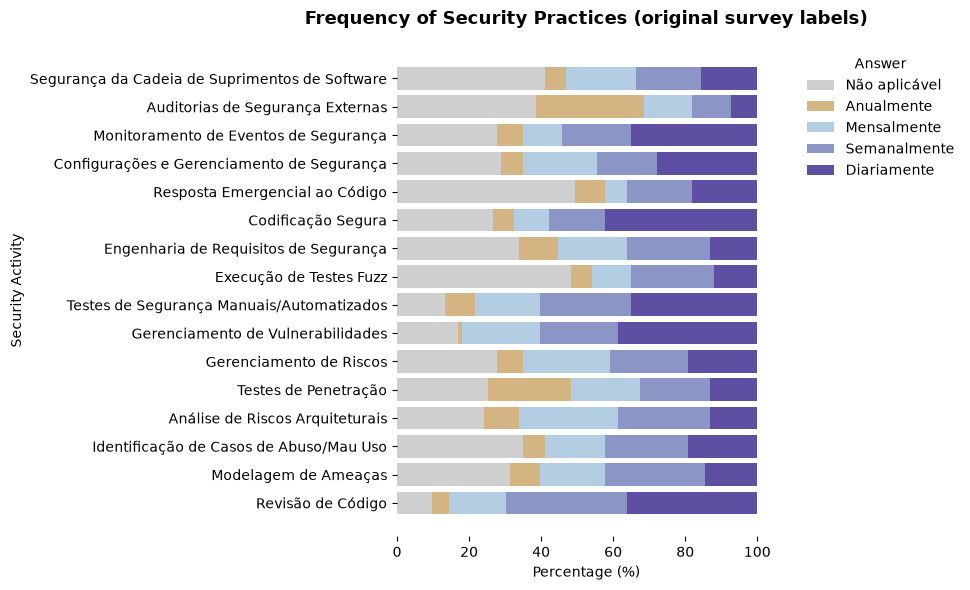

In [18]:
plot_bars(frequency_description, "Frequency of Security Practices (original survey labels)")

In [19]:
effectiveness_description

,Não Aplicável,Muito Baixo,Baixo,Moderado,Alto,Muito Alto
Revisão de Código,8,0,4,11,24,36
Modelagem de Ameaças,18,1,3,11,21,29
Identificação de Casos de Abuso/Mau Uso,14,1,6,19,20,23
Análise de Riscos Arquiteturais,12,1,2,12,24,32
Testes de Penetração,14,0,3,7,20,39
Gerenciamento de Riscos,14,1,3,6,26,33
Gerenciamento de Vulnerabilidades,10,0,3,12,18,40
Testes de Segurança Manuais/Automatizados,10,1,2,14,23,33
Execução de Testes Fuzz,24,3,12,18,13,13
Engenharia de Requisitos de Segurança,14,0,2,11,28,28


In [20]:
effectiveness_description.div(effectiveness_description.sum(axis=1), axis=0) * 100

,Não Aplicável,Muito Baixo,Baixo,Moderado,Alto,Muito Alto
Revisão de Código,9.638554,0.000000,4.819277,13.253012,28.915663,43.373494
Modelagem de Ameaças,21.686747,1.204819,3.614458,13.253012,25.301205,34.939759
Identificação de Casos de Abuso/Mau Uso,16.867470,1.204819,7.228916,22.891566,24.096386,27.710843
Análise de Riscos Arquiteturais,14.457831,1.204819,2.409639,14.457831,28.915663,38.554217
Testes de Penetração,16.867470,0.000000,3.614458,8.433735,24.096386,46.987952
Gerenciamento de Riscos,16.867470,1.204819,3.614458,7.228916,31.325301,39.759036
Gerenciamento de Vulnerabilidades,12.048193,0.000000,3.614458,14.457831,21.686747,48.192771
Testes de Segurança Manuais/Automatizados,12.048193,1.204819,2.409639,16.867470,27.710843,39.759036
Execução de Testes Fuzz,28.915663,3.614458,14.457831,21.686747,15.662651,15.662651
Engenharia de Requisitos de Segurança,16.867470,0.000000,2.409639,13.253012,33.734940,33.734940


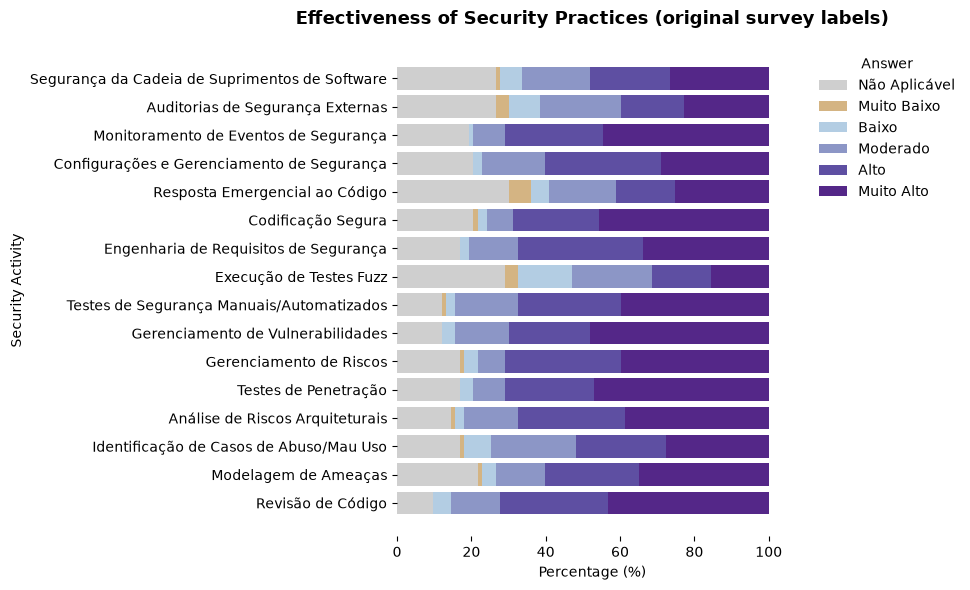

In [21]:
plot_bars(effectiveness_description, "Effectiveness of Security Practices (original survey labels)")

In [22]:
ease_of_use_description

,Não Aplicável,Muito Baixo,Baixo,Moderado,Alto,Muito Alto
Revisão de Código,11,2,9,26,17,18
Modelagem de Ameaças,20,2,13,24,16,8
Identificação de Casos de Abuso/Mau Uso,18,4,11,35,11,4
Análise de Riscos Arquiteturais,14,6,19,19,19,6
Testes de Penetração,15,7,14,21,12,14
Gerenciamento de Riscos,18,4,11,29,15,6
Gerenciamento de Vulnerabilidades,13,2,7,31,14,16
Testes de Segurança Manuais/Automatizados,13,4,11,21,21,13
Execução de Testes Fuzz,28,3,13,19,12,8
Engenharia de Requisitos de Segurança,20,2,13,21,25,2


In [23]:
ease_of_use_description.div(ease_of_use_description.sum(axis=1), axis=0) * 100

,Não Aplicável,Muito Baixo,Baixo,Moderado,Alto,Muito Alto
Revisão de Código,13.253012,2.409639,10.843373,31.325301,20.481928,21.686747
Modelagem de Ameaças,24.096386,2.409639,15.662651,28.915663,19.277108,9.638554
Identificação de Casos de Abuso/Mau Uso,21.686747,4.819277,13.253012,42.168675,13.253012,4.819277
Análise de Riscos Arquiteturais,16.867470,7.228916,22.891566,22.891566,22.891566,7.228916
Testes de Penetração,18.072289,8.433735,16.867470,25.301205,14.457831,16.867470
Gerenciamento de Riscos,21.686747,4.819277,13.253012,34.939759,18.072289,7.228916
Gerenciamento de Vulnerabilidades,15.662651,2.409639,8.433735,37.349398,16.867470,19.277108
Testes de Segurança Manuais/Automatizados,15.662651,4.819277,13.253012,25.301205,25.301205,15.662651
Execução de Testes Fuzz,33.734940,3.614458,15.662651,22.891566,14.457831,9.638554
Engenharia de Requisitos de Segurança,24.096386,2.409639,15.662651,25.301205,30.120482,2.409639


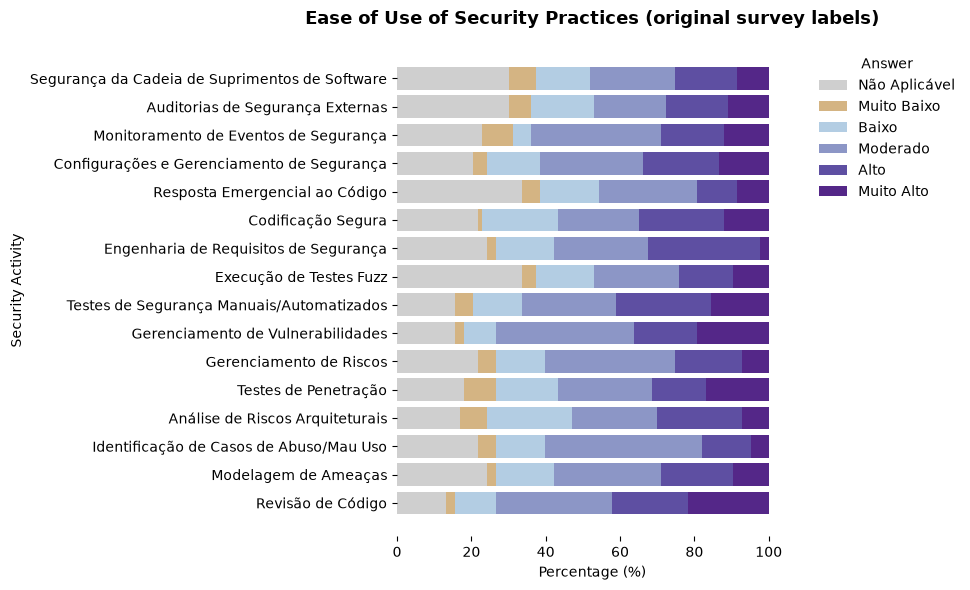

In [24]:
plot_bars(ease_of_use_description, "Ease of Use of Security Practices (original survey labels)")

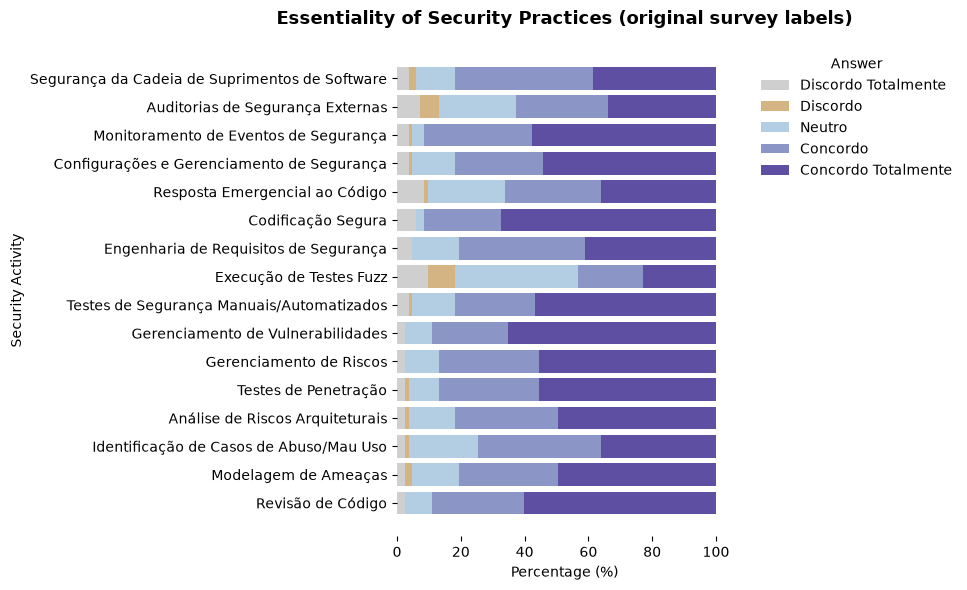

In [25]:
plot_bars(essentiality_description, "Essentiality of Security Practices (original survey labels)")

In [26]:
pt_names = ['Revisão de Código',
            'Modelagem de Ameaças',
            'Identificação de Casos de Abuso/Mau Uso',
            'Análise de Riscos Arquiteturais',
            'Testes de Penetração',
            'Gerenciamento de Riscos',
            'Gerenciamento de Vulnerabilidades',
            'Testes de Segurança Manuais/Automatizados',
            'Execução de Testes Fuzz',
            'Engenharia de Requisitos de Segurança',
            'Codificação Segura',
            'Resposta Emergencial ao Código',
            'Configurações e Gerenciamento de Segurança',
            'Monitoramento de Eventos de Segurança',
            'Auditorias de Segurança Externas',
            'Segurança da Cadeia de Suprimentos de Software']


en_names = ['Code Review',
            'Threat Modeling',
            'Identifying Abuse/Misuse Cases',
            'Architectural Risk Analysis',
            'Penetration Testing',
            'Risk Management',
            'Vulnerability Management',
            'Manual/Automated Security Testing',
            'Performing Fuzz Testing',
            'Security Requirements Engineering',
            'Secure Coding',
            'Emergency Codebase Response',
            'Security Configurations & Management',
            'Monitoring for Security Events',
            'Undergoing External Security Audits',
            'Software Supply Chain Security']

pt_en_mapping = dict(zip(pt_names, en_names))

In [27]:
frequency_map_pt_en = dict(zip(frequency_map.keys(), frequency_map_english.keys()))
essentiality_map_pt_en = dict(zip(essentiality_map.keys(), essentiality_map_english.keys()))
ease_of_use_map_pt_en = dict(zip(ease_of_use_map.keys(), ease_of_use_map_english.keys()))
effectiveness_map_pt_en = dict(zip(effectiveness_map.keys(), effectiveness_map_english.keys()))

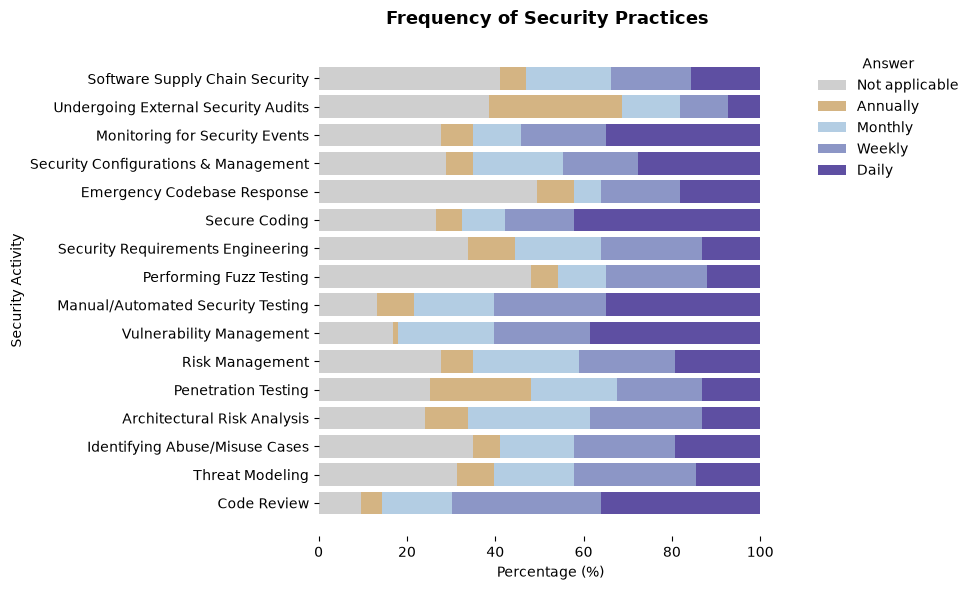

In [28]:
plot_bars(frequency_description.rename(columns=frequency_map_pt_en, index=pt_en_mapping),
            title="Frequency of Security Practices ")

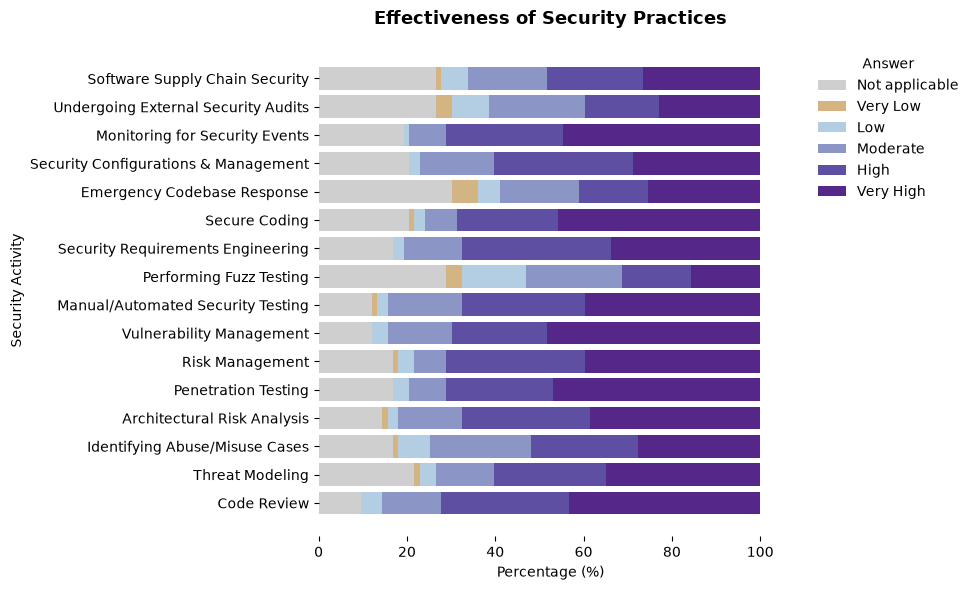

In [29]:
plot_bars(effectiveness_description.rename(columns=effectiveness_map_pt_en, index=pt_en_mapping),
         title="Effectiveness of Security Practices")

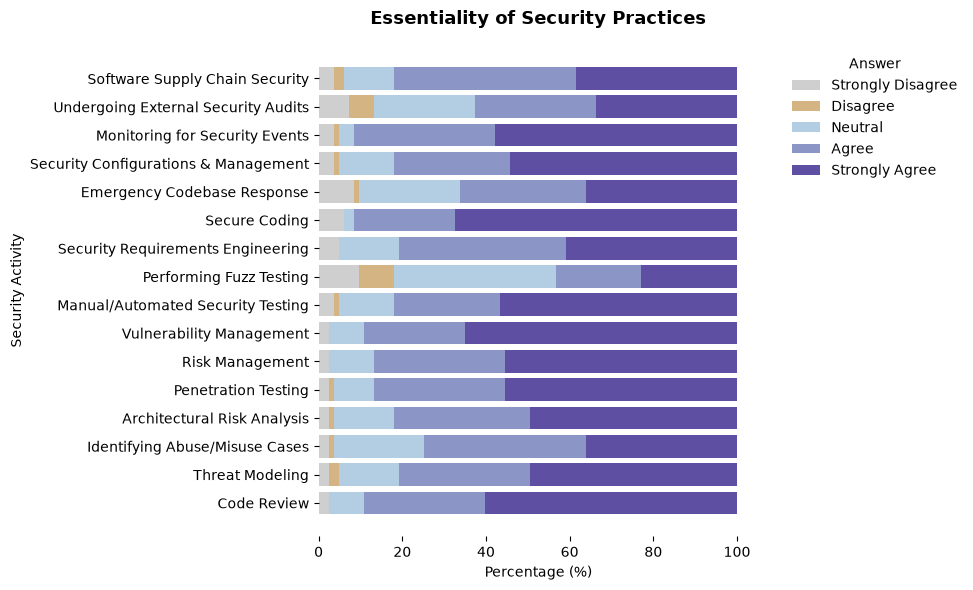

In [30]:
plot_bars(essentiality_description.rename(columns=essentiality_map_pt_en, index=pt_en_mapping),
         title="Essentiality of Security Practices")

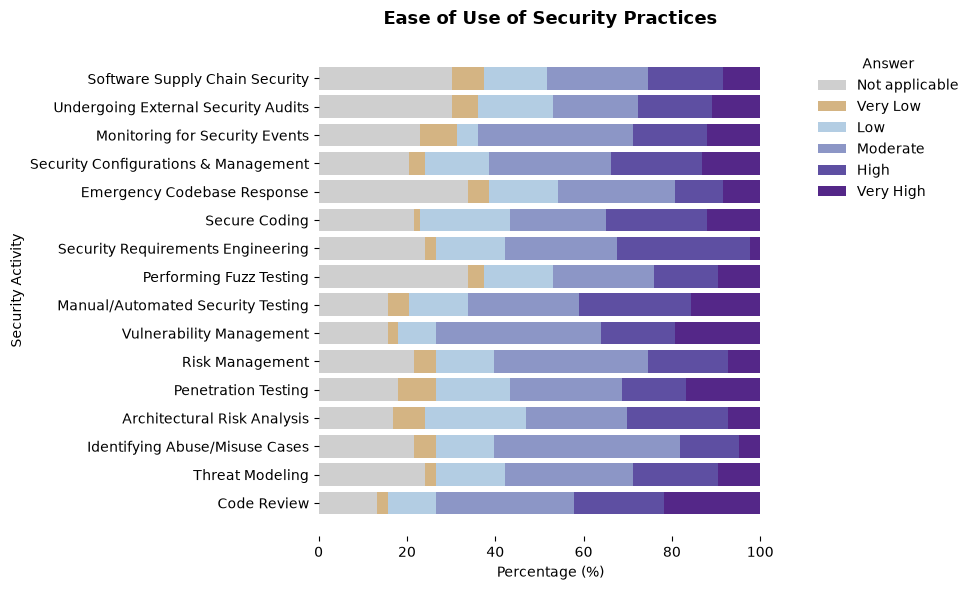

In [31]:
plot_bars(ease_of_use_description.rename(columns=ease_of_use_map_pt_en, index=pt_en_mapping),
         title="Ease of Use of Security Practices")

In [32]:
df[essentiality_cols[0]].unique()

<StringArray>
['Concordo', 'Concordo Totalmente', 'Neutro', 'Discordo Totalmente']
Length: 4, dtype: str

In [33]:
for column in frequency_cols:
  df[column] = df[column].map(frequency_map)

for column in effectiveness_cols:
  df[column] = df[column].map(effectiveness_map)

for column in ease_of_use_cols:
  df[column] = df[column].map(ease_of_use_map)

for column in essentiality_cols:
  df[column] = df[column].map(essentiality_map)

In [34]:
df['Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?'].unique()

<StringArray>
['Entre 7 e 14 anos',  'Entre 4 e 5 anos',  'Entre 1 e 3 anos',
    'Menos de 1 ano',   'Mais de 15 anos']
Length: 5, dtype: str

In [35]:
experience_column = 'Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'
dev_experience_years_column = 'Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?'
security_experience_years_column = 'Quantos anos de experiência você tem em funções relacionadas a Segurança de Software?'
education_level_column = 'Qual é o seu nível de educação formal concluída?'
seniority_column = 'Por favor, indique a senioridade da posição que ocupa.'
specialists_column = 'Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?'
certification_column = 'Você possui alguma certificação na área de segurança da informação? Se sim, quais são elas?'

has_experience = 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.'

# Roles explicitly focused on software or information security. DevOps engineer
# alone is not considered evidence of security specialization; participants who
# also selected one of these roles remain specialists (roles are multiple choice)
specialist_responses = ["Cryptographer", "Penetration tester", "Privacy engineer", "Security engineer"]
no_certification_responses = ["Não possui nenhuma certificação"]
# Security roles written by participants in the "Outros" (free text) field of Q6
specialist_other_roles = [
    "SOC",
    "Gerente de Segurança da Informação",
    "Application secure",
    "Security Analyst",
    "Appsec",
    "AppSec",
    "Cybersegurança",
    "Security Champion",
    "Arquiteto de Segurança",
    "Information Security Analisty I / IAM",
    "Appsec & DevSecOps",
]


# The role question is multiple choice: answers come as a comma-separated
# string, so each selected role (predefined or written in "Outros") is checked
def is_specialist(answer):
    selected_roles = [role.strip() for role in str(answer).split(',')]
    return int(any(role in specialist_responses or role in specialist_other_roles
                   for role in selected_roles))

non_security_certifications = ["SCRUM", "AWS", "AWS Practitioner", "Azure", "CASE", "CASE Java", "AWS e Azure", "Não possui nenhuma certificação"]


In [36]:
df["Number of security certifications"] = (
    df[certification_column]
    .fillna("")  
    .str.split(",") 
    .apply(lambda certs: sum(
        c.strip() not in non_security_certifications  
        for c in certs
    ))
)


In [37]:
df[[certification_column, "Number of security certifications"]]

,"Você possui alguma certificação na área de segurança da informação? Se sim, quais são elas?",Number of security certifications
1,Não possui nenhuma certificação,0
2,Não possui nenhuma certificação,0
3,Não possui nenhuma certificação,0
4,eWPTX,1
5,"Certified Ethical Hacker (CEH), CompTIA Security+",2
6,Não possui nenhuma certificação,0
7,Não possui nenhuma certificação,0
9,"DCPT, ISO 27001",2
10,Não possui nenhuma certificação,0
11,Não possui nenhuma certificação,0


In [38]:
print(df['Qual é o seu nível de educação formal concluída?'].unique())
print(df[seniority_column].unique())
print(df[dev_experience_years_column].unique())
print(df[security_experience_years_column].unique())


<StringArray>
[              'Mestrado', 'Estudante de Doutorado',        'Ensino Superior',
              'Doutorado',         'Especialização',           'Ensino Médio',
  'Estudante de Mestrado']
Length: 7, dtype: str
<StringArray>
['Sênior (10+ anos)', 'Júnior (até 5 anos)', 'Pleno (6 a 9 anos)',
 'Estagiário']
Length: 4, dtype: str
<StringArray>
['Entre 7 e 14 anos',  'Entre 4 e 5 anos',  'Entre 1 e 3 anos',
    'Menos de 1 ano',   'Mais de 15 anos']
Length: 5, dtype: str
<StringArray>
['Entre 7 e 14 anos',           'Nenhuma',  'Entre 1 e 3 anos',
  'Entre 4 e 6 anos',    'Menos de 1 ano',   'Mais de 15 anos']
Length: 6, dtype: str


In [39]:
len(df[~df[specialists_column].apply(is_specialist).astype(bool)][specialists_column].unique())

12

In [40]:
df[~df[specialists_column].apply(is_specialist).astype(bool)][specialists_column].unique()

<StringArray>
[                                                 'Developer (Backend, frontend, fullstack)',
                                                                           'DevOps engineer',
                                                       'DevOps engineer, Solution Architect',
                                                 'Solution Architect, Test Manager / Tester',
                                                                        'Solution Architect',
                                                                                'Consulting',
                                               'DevOps engineer, Sustentação/Infraestrutura',
                 'Data Scientist, Developer (Backend, frontend, fullstack), DevOps engineer',
 'Developer (Backend, frontend, fullstack), DevOps engineer, Project Lead / Project Manager',
                                                            'Project Lead / Project Manager',
                                              

In [41]:
print("Number of specialists:", df[df[specialists_column].apply(is_specialist).astype(bool)].shape[0])
print("Number of non-specialists:", df[~df[specialists_column].apply(is_specialist).astype(bool)].shape[0])

Number of specialists: 57
Number of non-specialists: 26


In [42]:
df_direct_experience = df[df[experience_column] == has_experience]
df_indirect_experience = df[df[experience_column] != has_experience]

df_direct_experience.shape


(62, 103)

In [43]:
df[seniority_column].unique()

<StringArray>
['Sênior (10+ anos)', 'Júnior (até 5 anos)', 'Pleno (6 a 9 anos)',
 'Estagiário']
Length: 4, dtype: str

In [44]:
print(df['Qual é o seu nível de educação formal concluída?'].unique())
print(df[seniority_column].unique())
print(df[dev_experience_years_column].unique())
print(df[security_experience_years_column].unique())


<StringArray>
[              'Mestrado', 'Estudante de Doutorado',        'Ensino Superior',
              'Doutorado',         'Especialização',           'Ensino Médio',
  'Estudante de Mestrado']
Length: 7, dtype: str
<StringArray>
['Sênior (10+ anos)', 'Júnior (até 5 anos)', 'Pleno (6 a 9 anos)',
 'Estagiário']
Length: 4, dtype: str
<StringArray>
['Entre 7 e 14 anos',  'Entre 4 e 5 anos',  'Entre 1 e 3 anos',
    'Menos de 1 ano',   'Mais de 15 anos']
Length: 5, dtype: str
<StringArray>
['Entre 7 e 14 anos',           'Nenhuma',  'Entre 1 e 3 anos',
  'Entre 4 e 6 anos',    'Menos de 1 ano',   'Mais de 15 anos']
Length: 6, dtype: str


In [45]:
education_level_map = {
    'Ensino Médio': 1,
    'Ensino Superior': 2,
    'Especialização': 3,
    'Estudante de Mestrado': 4,
    'Mestrado': 5,
    'Estudante de Doutorado': 6,
    'Doutorado': 7
}

seniority_map = {
    'Estagiário': 1,
    'Júnior (até 5 anos)': 2,
    'Pleno (6 a 9 anos)': 3,
    'Sênior (10+ anos)': 4
}

dev_experience_years_map = {
    'Menos de 1 ano': 1,
    'Entre 1 e 3 anos': 2,
    'Entre 4 e 5 anos': 3,
    'Entre 7 e 14 anos': 4,
    'Mais de 15 anos': 5
}

security_experience_years_map = {
    'Nenhuma': 0,
    'Menos de 1 ano': 1,
    'Entre 1 e 3 anos': 2,
    'Entre 4 e 6 anos': 3,
    'Entre 7 e 14 anos': 4,
    'Mais de 15 anos': 5
}


def direct_experience_specialist_interaction(row):
    if row['specialist'] and row['direct_experience']:
        return 3
    elif row['direct_experience'] and not row['specialist']:
        return 2
    else:
        return 1


def direct_experience_specialist_relation(row):
    return (row['specialist'] + row['direct_experience']) / 2


df[dev_experience_years_column] = df[dev_experience_years_column].map(dev_experience_years_map)

df[seniority_column] = df[seniority_column].map(seniority_map)

df[security_experience_years_column] = df[security_experience_years_column].map(security_experience_years_map)

df['specialist'] = df[specialists_column].apply(is_specialist)

df['direct_experience'] = df[experience_column].apply(lambda x: 1 if x == has_experience else 0)

df['certification'] = df[certification_column].apply(lambda x: 0 if x in no_certification_responses else 1)

df['Qual é o seu nível de educação formal concluída?'] = df['Qual é o seu nível de educação formal concluída?'].map(education_level_map)

df['direct_experience_specialist_interaction'] = df.apply(direct_experience_specialist_interaction, axis=1)

df['direct_experience_specialist_relation'] = df.apply(direct_experience_specialist_relation, axis=1)


In [46]:
print(df['Qual é o seu nível de educação formal concluída?'].unique())
print(df[seniority_column].unique())
print(df[dev_experience_years_column].unique())
print(df[security_experience_years_column].unique())

[5 6 2 7 3 1 4]
[4 2 3 1]
[4 3 2 1 5]
[4 0 2 3 1 5]


In [47]:
df['specialist'].sum()

np.int64(57)

In [48]:
print("Total:",df.shape[0])
print(f"Percentage with direct experience: {(df_direct_experience.shape[0]/ df.shape[0])*100:.3f}%")
print(f"Percentage with indirect experience: {(df_indirect_experience.shape[0]/ df.shape[0])*100:.3f}%")

Total: 83
Percentage with direct experience: 74.699%
Percentage with indirect experience: 25.301%


In [49]:
df['direct_experience_specialist_relation'].value_counts()

direct_experience_specialist_relation
1.0    52
0.0    16
0.5    15
Name: count, dtype: int64

In [50]:
df_frequency = df[frequency_cols].copy()
df_ease_of_use = df[ease_of_use_cols].copy()
df_effectiveness = df[effectiveness_cols].copy()
df_essentiality = df[essentiality_cols].copy()


In [51]:
df_ease_of_use

,"Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Revisão de Código]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Modelagem de Ameaças]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Identificação de Casos de Abuso/Mau Uso]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Análise de Riscos Arquiteturais]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Testes de Penetração]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Gerenciamento de Riscos]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Gerenciamento de Vulnerabilidades]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Testes de Segurança Manuais/Automatizados]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Execução de Testes Fuzz]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Engenharia de Requisitos de Segurança]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Codificação Segura]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Resposta Emergencial ao Código]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Configurações e Gerenciamento de Segurança]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Monitoramento de Eventos de Segurança]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Auditorias de Segurança Externas]","Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Segurança da Cadeia de Suprimentos de Software]"
1,1,3,3,3,3,4,3,3,2,3,2,3,3,3,2,2
2,5,0,0,0,0,0,3,4,0,0,3,0,3,0,0,0
3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
4,5,5,4,3,5,5,5,5,5,5,4,3,3,1,1,4
5,2,3,3,2,3,3,

In [52]:
education_level = df['Qual é o seu nível de educação formal concluída?']
dev_experience_years = df['Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?']
security_experience_years = df['Quantos anos de experiência você tem em funções relacionadas a Segurança de Software?']
seniority = df['Por favor, indique a senioridade da posição que ocupa.']
direct_experience_specialist_interaction_col = df['direct_experience_specialist_interaction']
direct_experience_specialist_relation_col = df['direct_experience_specialist_relation']
security_certifications_count = df["Number of security certifications"]

# weight formula 1
# df['weight'] = (0.3*education_level) + (0.25*dev_experience_years) + (0.2*seniority) + (0.25*direct_experience_specialist_interaction_col)

# weight formula 2
# df_final['weight'] = (education_level/education_level.nunique()) + (dev_experience_years/dev_experience_years.median()) + (seniority/seniority.median()) + direct_experience_specialist_relation_col

# All participants have the same weight (1), so the weighted means below are simple means
df['weight'] = 1

total_values_ease_of_use = {}
total_values_frequency = {}
total_values_effectiveness = {}
total_values_essentiality = {}

total_values_ease_of_use_normalized = {}
total_values_frequency_normalized = {}
total_values_effectiveness_normalized = {}
total_values_essentiality_normalized = {}


for column in df.columns:
    df_without_na = df[df[column] != 0]  # remove the 'not applicable'

    if column in frequency_cols:
        print(f"Frequency ({column}):", df_without_na['weight'].sum())
        total_values_frequency[column] = (df_without_na[column] * df_without_na['weight']).sum()
        total_values_frequency_normalized[column] = (
            (df_without_na[column] * df_without_na['weight']).sum()
            / (df_without_na['weight'].sum() * 4)
        )

    if column in ease_of_use_cols:
        print(f"Ease of use ({column}):", df_without_na['weight'].sum())
        total_values_ease_of_use[column] = (df_without_na[column] * df_without_na['weight']).sum()
        total_values_ease_of_use_normalized[column] = (
            (df_without_na[column] * df_without_na['weight']).sum()
            / (df_without_na['weight'].sum() * 5)
        )

    if column in effectiveness_cols:
        print(f"Effectiveness ({column}):", df_without_na['weight'].sum())
        total_values_effectiveness[column] = (df_without_na[column] * df_without_na['weight']).sum()
        total_values_effectiveness_normalized[column] = (
            (df_without_na[column] * df_without_na['weight']).sum()
            / (df_without_na['weight'].sum() * 5)
        )

    if column in essentiality_cols:
        print(f"Essentiality ({column}):", df_without_na['weight'].sum())
        total_values_essentiality[column] = (df_without_na[column] * df_without_na['weight']).sum()
        total_values_essentiality_normalized[column] = (
            (df_without_na[column] * df_without_na['weight']).sum()
            / (df_without_na['weight'].sum() * 5)
        )

for column in df.columns:
    if column in ease_of_use_cols + effectiveness_cols + frequency_cols + essentiality_cols:
        df[column] = df[column] * df['weight']


Frequency (Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Revisão de Código]): 75
Frequency (Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Modelagem de Ameaças]): 57
Frequency (Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Identificação de Casos de Abuso/Mau Uso]): 54
Frequency (Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Análise de Riscos Arquiteturais]): 63
Frequency (Com que frequência você costuma aplicar as seguintes práticas de segur

In [53]:
means = []

for col in df_effectiveness.columns:
    means.append(df_effectiveness.loc[df_effectiveness[col].isin([1, 2, 3, 4, 5]).values, col].mean())

In [54]:
total_values_frequency

{'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Revisão de Código]': np.int64(234),
 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Modelagem de Ameaças]': np.int64(154),
 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Identificação de Casos de Abuso/Mau Uso]': np.int64(154),
 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Análise de Riscos Arquiteturais]': np.int64(161),
 'Com que frequência você costuma aplicar as seguintes práticas de se

In [55]:
df['weight'].sum()

np.int64(83)

In [56]:
total_values_effectiveness_normalized

{'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Revisão de Código]': np.float64(0.8453333333333334),
 'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Modelagem de Ameaças]': np.float64(0.8276923076923077),
 'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Identificação de Casos de Abuso/Mau Uso]': np.float64(0.7681159420289855),
 'Com base e

In [57]:
total_values_ease_of_use_normalized

{'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Revisão de Código]': np.float64(0.7111111111111111),
 'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Modelagem de Ameaças]': np.float64(0.6476190476190476),
 'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Identificação de Casos de Abuso/Mau Uso]': np.float64(0.6),
 'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliz

In [58]:
total_values_frequency_normalized

{'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Revisão de Código]': np.float64(0.78),
 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Modelagem de Ameaças]': np.float64(0.6754385964912281),
 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Identificação de Casos de Abuso/Mau Uso]': np.float64(0.7129629629629629),
 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Análise de Riscos Arquiteturais]': np.float64(0.6388888888888888),
 'Com que frequ

In [59]:
total_values_essentiality_normalized

{'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Revisão de Código]': np.float64(0.8891566265060241),
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Modelagem de Ameaças]': np.float64(0.8457831325301205),
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Identificação de Casos de Abuso/Mau Uso]': np.float64(0.8096385542168675),
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Análise de Riscos Arquiteturais]': np.float64(0.8506024096385543),
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Testes de Penetração]': np.float64(0.87

In [60]:
print(len(total_values_effectiveness_normalized))
print(len(total_values_ease_of_use_normalized))
print(len(total_values_frequency_normalized))
print(len(total_values_essentiality_normalized))

16
16
16
16


In [61]:
ease_of_use_normalized_df = pd.DataFrame({
    'Practice': practices_en,
    'Ease of use': list(total_values_ease_of_use_normalized.values())
})

effectiveness_normalized_df = pd.DataFrame({
    'Practice': practices_en,
    'Effectiveness': list(total_values_effectiveness_normalized.values())
})

frequency_normalized_df = pd.DataFrame({
    'Practice': practices_en,
    'Frequency of use': list(total_values_frequency_normalized.values())
})

essentiality_normalized_df = pd.DataFrame({
    'Practice': practices_en,
    'Essentiality': list(total_values_essentiality_normalized.values())
})


In [62]:
def bold_text(val):
    return 'font-weight: bold'

def apply_percent(x):
    return f'{x*100:.2f}%'

final = ease_of_use_normalized_df.merge(effectiveness_normalized_df, on='Practice').merge(frequency_normalized_df, on='Practice').merge(essentiality_normalized_df, on='Practice')

from pathlib import Path
results_path = Path('results/RQ1')
results_path.mkdir(parents=True, exist_ok=True)

final.to_excel(results_path / 'comparison_categories.xlsx')

final.style.background_gradient(cmap='RdYlGn', low=0.3, high=0.4).map(bold_text)

,Practice,Ease of use,Effectiveness,Frequency of use,Essentiality
0,Code Review,0.711111,0.845333,0.780000,0.889157
1,Threat Modeling,0.647619,0.827692,0.675439,0.845783
2,Identifying Abuse/Misuse Cases,0.600000,0.768116,0.712963,0.809639
3,Architectural Risk Analysis,0.600000,0.836620,0.638889,0.850602
4,Penetration Testing,0.635294,0.875362,0.576613,0.872289
5,Risk Management,0.624615,0.852174,0.683333,0.874699
6,Vulnerability Management,0.700000,0.860274,0.793478,0.898795
7,Manual/Automated Security Testing,0.680000,0.832877,0.750000,0.860241
8,Performing Fuzz Testing,0.632727,0.671186,0.697674,0.677108
9,Security Requirements Engineering,0.638095,0.837681,0.645455,0.824096


In [63]:
df['direct_experience_specialist_relation'].isna().sum()

np.int64(0)

In [64]:
df_ease_of_use_weighted = df[ease_of_use_cols].copy()
df_effectiveness_weighted = df[effectiveness_cols].copy()
df_frequency_weighted = df[frequency_cols].copy()
df_essentiality_weighted = df[essentiality_cols].copy()


In [65]:
# If x = 1 or 2, it means the usage is not easy.
def ease_of_use_converting(x):
  return 0 if x == 1 or x == 2 else 1

# If x = 4 or 5, it is said to be effective.
def effectiveness_converting(x):
    return 0 if x == 1 or x == 2 or x == 3 else 1

df_ease_of_use_converted = df_ease_of_use.copy()
df_effectiveness_converted = df_effectiveness.copy()

for column in df_ease_of_use.columns:
    df_ease_of_use_converted.loc[:, f'{column}'] = df_ease_of_use.loc[:, column].apply(ease_of_use_converting).copy()

for column in df_effectiveness.columns:
    df_effectiveness_converted.loc[:, f'{column}'] = df_effectiveness.loc[:, column].apply(effectiveness_converting).copy()

In [66]:
effectiveness_array = []
ease_of_use_array = []

for i in range(len(df_ease_of_use.columns)):
  practice = practices[i]

  df_ease_of_use_practice_converted = df_ease_of_use_converted.iloc[:, i]
  df_effectiveness_practice_converted = df_effectiveness_converted.iloc[:, i]

  ease_of_use_share = df_ease_of_use_practice_converted.sum() / len(df_ease_of_use_practice_converted)
  effectiveness_share = df_effectiveness_practice_converted.sum() / len(df_effectiveness_practice_converted)

  ease_of_use_array.append(ease_of_use_share)
  effectiveness_array.append(effectiveness_share)

percents_df = pd.DataFrame({
    'Practice': practices_en,
    'Ease of use': ease_of_use_array,
    'Effectiveness': effectiveness_array
})

In [67]:
percents_df = percents_df.set_index('Practice')

In [68]:
ease_of_use_array

[np.float64(0.8674698795180723),
 np.float64(0.8192771084337349),
 np.float64(0.8192771084337349),
 np.float64(0.6987951807228916),
 np.float64(0.7469879518072289),
 np.float64(0.8192771084337349),
 np.float64(0.891566265060241),
 np.float64(0.8192771084337349),
 np.float64(0.8072289156626506),
 np.float64(0.8192771084337349),
 np.float64(0.7831325301204819),
 np.float64(0.7951807228915663),
 np.float64(0.8192771084337349),
 np.float64(0.8674698795180723),
 np.float64(0.7710843373493976),
 np.float64(0.7831325301204819)]

In [69]:
percents_df.style.background_gradient(cmap='RdYlGn', low=0.3, high=0.4).map(bold_text)

,Ease of use,Effectiveness
Practice,,
Code Review,0.867470,0.819277
Threat Modeling,0.819277,0.819277
Identifying Abuse/Misuse Cases,0.819277,0.686747
Architectural Risk Analysis,0.698795,0.819277
Penetration Testing,0.746988,0.879518
Risk Management,0.819277,0.879518
Vulnerability Management,0.891566,0.819277
Manual/Automated Security Testing,0.819277,0.795181
Performing Fuzz Testing,0.807229,0.602410


# Correlations

In [70]:
from scipy.stats import spearmanr


def holm_bonferroni(p_values: pd.Series) -> pd.Series:
    """
    Returns the Holm-Bonferroni adjusted p-values, ignoring missing values.
    """
    valid = p_values.dropna().sort_values()
    m = len(valid)

    # Step-down adjustment: p_(i) * (m - i + 1), forced to be monotonic and capped at 1
    adjusted = (valid * np.arange(m, 0, -1)).cummax().clip(upper=1)

    return adjusted.reindex(p_values.index)


def spearman_without_na(x: pd.Series, y: pd.Series):
    """
    Spearman correlation using only participants who rated both dimensions:
    'Não Aplicável' (Not Applicable) is coded as 0 and is not the lowest point of the scale.
    """
    answered = (x != 0) & (y != 0)
    return spearmanr(x[answered], y[answered])


def calc_correlations(df_frequency, df_effectiveness, df_ease_of_use, df_essentiality):
    correlations_effectiveness_frequency = {}
    correlations_effectiveness_ease_of_use = {}
    correlations_frequency_ease_of_use = {}
    correlations_frequency_essentiality = {}
    correlations_effectiveness_essentiality = {}
    correlations_ease_of_use_essentiality = {}

    p_values_freq_eff = {}
    p_values_effectiveness_ease_of_use = {}
    p_values_frequency_ease_of_use = {}
    p_values_frequency_essentiality = {}
    p_values_effectiveness_essentiality = {}
    p_values_ease_of_use_essentiality = {}
    

    for i in range(len(df_frequency.columns)):
        practice = practices_en[i]

        df_frequency_practice = df_frequency.iloc[:, i]
        df_effectiveness_practice = df_effectiveness.iloc[:, i]
        df_ease_of_use_practice = df_ease_of_use.iloc[:, i]
        df_essentiality_practice = df_essentiality.iloc[:, i]

        correlation_freq_eff, p_value_freq_eff = spearman_without_na(df_frequency_practice, df_effectiveness_practice)
        correlation_freq_ease, p_value_freq_ease = spearman_without_na(df_frequency_practice, df_ease_of_use_practice)
        correlation_eff_ease, p_value_eff_ease = spearman_without_na(df_effectiveness_practice, df_ease_of_use_practice)
        correlation_freq_ess, p_value_freq_ess = spearman_without_na(df_frequency_practice, df_essentiality_practice)
        correlation_eff_ess, p_value_eff_ess = spearman_without_na(df_effectiveness_practice, df_essentiality_practice)
        correlation_ease_ess, p_value_ease_ess = spearman_without_na(df_ease_of_use_practice, df_essentiality_practice)
        

        correlations_effectiveness_frequency[f'Frequency x Effectiveness in {practice}'] = correlation_freq_eff.round(3)
        p_values_freq_eff[f'Frequency x Effectiveness in {practice}'] = p_value_freq_eff

        correlations_effectiveness_ease_of_use[f'Effectiveness x Ease of use in {practice}'] = correlation_eff_ease.round(3)
        p_values_effectiveness_ease_of_use[f'Effectiveness x Ease of use in {practice}'] = p_value_eff_ease

        correlations_frequency_ease_of_use[f'Frequency x Ease of use in {practice}'] = correlation_freq_ease.round(3)
        p_values_frequency_ease_of_use[f'Frequency x Ease of use in {practice}'] = p_value_freq_ease

        correlations_frequency_essentiality[f'Frequency x Essentiality in {practice}'] = correlation_freq_ess.round(3)
        p_values_frequency_essentiality[f'Frequency x Essentiality in {practice}'] = p_value_freq_ess

        correlations_effectiveness_essentiality[f'Effectiveness x Essentiality in {practice}'] = correlation_eff_ess.round(3)
        p_values_effectiveness_essentiality[f'Effectiveness x Essentiality in {practice}'] = p_value_eff_ess

        correlations_ease_of_use_essentiality[f'Ease of use x Essentiality in {practice}'] = correlation_ease_ess.round(3)
        p_values_ease_of_use_essentiality[f'Ease of use x Essentiality in {practice}'] = p_value_ease_ess


    correlations_effectiveness_ease_of_use_df = pd.DataFrame({
        'Practice': list(correlations_effectiveness_ease_of_use.keys()),
        'Correlation (Eff, Ease)': list(correlations_effectiveness_ease_of_use.values()),
        'p-value': list(p_values_effectiveness_ease_of_use.values())
    })

    correlations_frequency_ease_of_use_df = pd.DataFrame({
        'Practice': list(correlations_frequency_ease_of_use.keys()),
        'Correlation (Freq, Ease)': list(correlations_frequency_ease_of_use.values()),
        'p-value': list(p_values_frequency_ease_of_use.values())
    })

    correlations_effectiveness_frequency_df = pd.DataFrame({
        'Practice': list(correlations_effectiveness_frequency.keys()),
        'Correlation (Eff, Freq)': list(correlations_effectiveness_frequency.values()),
        'p-value': list(p_values_freq_eff.values())
    })

    correlations_effectiveness_essentiality_df = pd.DataFrame({
        'Practice': list(correlations_effectiveness_essentiality.keys()),
        'Correlation (Eff, Ess)': list(correlations_effectiveness_essentiality.values()),
        'p-value': list(p_values_effectiveness_essentiality.values())
    })

    correlations_ease_of_use_essentiality_df = pd.DataFrame({
        'Practice': list(correlations_ease_of_use_essentiality.keys()),
        'Correlation (Ease, Ess)': list(correlations_ease_of_use_essentiality.values()),
        'p-value': list(p_values_ease_of_use_essentiality.values())
    })

    correlations_frequency_essentiality_df = pd.DataFrame({
        'Practice': list(correlations_frequency_essentiality.keys()),
        'Correlation (Freq, Ess)': list(correlations_frequency_essentiality.values()),
        'p-value': list(p_values_frequency_essentiality.values())
    })

    # Holm-Bonferroni correction: each pair of attributes (16 practices) is a family of tests
    for correlation_df in (
        correlations_effectiveness_ease_of_use_df,
        correlations_frequency_ease_of_use_df,
        correlations_effectiveness_frequency_df,
        correlations_effectiveness_essentiality_df,
        correlations_ease_of_use_essentiality_df,
        correlations_frequency_essentiality_df,
    ):
        correlation_df['p-value (Holm)'] = holm_bonferroni(correlation_df['p-value'])

    def highlight_significant(series):
            return ['font-weight: bold' if v < 0.05 else '' for v in series]

    def highlight_strong_corr(value):
        return 'font-weight: bold' if (value > 0.5 or value < -0.5) else ''

    correlations_effectiveness_frequency_df_styled = correlations_effectiveness_frequency_df.style.map(highlight_strong_corr, subset=['Correlation (Eff, Freq)'])
    correlations_effectiveness_frequency_df = correlations_effectiveness_frequency_df_styled.apply(highlight_significant, subset=['p-value (Holm)'])

    correlations_effectiveness_ease_of_use_df_styled = correlations_effectiveness_ease_of_use_df.style.map(highlight_strong_corr, subset=['Correlation (Eff, Ease)'])
    correlations_effectiveness_ease_of_use_df = correlations_effectiveness_ease_of_use_df_styled.apply(highlight_significant, subset=['p-value (Holm)'])

    correlations_frequency_ease_of_use_df_styled = correlations_frequency_ease_of_use_df.style.map(highlight_strong_corr, subset=['Correlation (Freq, Ease)'])
    correlations_frequency_ease_of_use_df = correlations_frequency_ease_of_use_df_styled.apply(highlight_significant, subset=['p-value (Holm)'])

    correlations_frequency_essentiality_df_styled = correlations_frequency_essentiality_df.style.map(highlight_strong_corr, subset=['Correlation (Freq, Ess)'])
    correlations_frequency_essentiality_df = correlations_frequency_essentiality_df_styled.apply(highlight_significant, subset=['p-value (Holm)'])

    correlation_eff_ess_df_styled = correlations_effectiveness_essentiality_df.style.map(highlight_strong_corr, subset=['Correlation (Eff, Ess)'])
    correlation_eff_ess_df = correlation_eff_ess_df_styled.apply(highlight_significant, subset=['p-value (Holm)'])

    correlation_ease_ess_df_styled = correlations_ease_of_use_essentiality_df.style.map(highlight_strong_corr, subset=['Correlation (Ease, Ess)'])
    correlation_ease_ess_df = correlation_ease_ess_df_styled.apply(highlight_significant, subset=['p-value (Holm)'])


    return correlations_effectiveness_frequency_df, correlations_effectiveness_ease_of_use_df, correlations_frequency_ease_of_use_df, correlations_frequency_essentiality_df, correlation_eff_ess_df, correlation_ease_ess_df


In [71]:
correlations_effectiveness_frequency_df, \
correlations_effectiveness_ease_of_use_df, \
correlations_frequency_ease_of_use_df, \
correlations_frequency_essentiality_df, \
correlation_effectiveness_essentiality_df, \
correlation_ease_of_use_essentiality_df = calc_correlations(
    df_frequency,
    df_effectiveness,
    df_ease_of_use,
    df_essentiality
)


In [72]:
correlations_effectiveness_frequency_df

,Practice,"Correlation (Eff, Freq)",p-value,p-value (Holm)
0,Frequency x Effectiveness in Code Review,0.175000,0.139129,1.000000
1,Frequency x Effectiveness in Threat Modeling,0.010000,0.942909,1.000000
2,Frequency x Effectiveness in Identifying Abuse/Misuse Cases,0.289000,0.037375,0.560618
3,Frequency x Effectiveness in Architectural Risk Analysis,0.043000,0.738605,1.000000
4,Frequency x Effectiveness in Penetration Testing,0.017000,0.900258,1.000000
5,Frequency x Effectiveness in Risk Management,-0.002000,0.985827,1.000000
6,Frequency x Effectiveness in Vulnerability Management,0.152000,0.222201,1.000000
7,Frequency x Effectiveness in Manual/Automated Security Testing,0.095000,0.439697,1.000000
8,Frequency x Effectiveness in Performing Fuzz Testing,0.226000,0.144728,1.000000
9,Frequency x Effectiveness in Security Requirements Engineering,0.175000,0.211152,1.000000


In [73]:
correlations_effectiveness_ease_of_use_df

,Practice,"Correlation (Eff, Ease)",p-value,p-value (Holm)
0,Effectiveness x Ease of use in Code Review,0.339000,0.003538,0.049535
1,Effectiveness x Ease of use in Threat Modeling,0.268000,0.036635,0.329715
2,Effectiveness x Ease of use in Identifying Abuse/Misuse Cases,0.294000,0.019247,0.211713
3,Effectiveness x Ease of use in Architectural Risk Analysis,0.184000,0.134071,0.670356
4,Effectiveness x Ease of use in Penetration Testing,0.231000,0.064021,0.396321
5,Effectiveness x Ease of use in Risk Management,0.127000,0.318007,0.954022
6,Effectiveness x Ease of use in Vulnerability Management,0.162000,0.187651,0.750602
7,Effectiveness x Ease of use in Manual/Automated Security Testing,0.110000,0.369971,0.954022
8,Effectiveness x Ease of use in Performing Fuzz Testing,0.383000,0.004241,0.055138
9,Effectiveness x Ease of use in Security Requirements Engineering,0.264000,0.038223,0.329715


In [74]:
correlations_frequency_ease_of_use_df

,Practice,"Correlation (Freq, Ease)",p-value,p-value (Holm)
0,Frequency x Ease of use in Code Review,0.120000,0.318426,1.000000
1,Frequency x Ease of use in Threat Modeling,0.135000,0.324149,1.000000
2,Frequency x Ease of use in Identifying Abuse/Misuse Cases,0.136000,0.333312,1.000000
3,Frequency x Ease of use in Architectural Risk Analysis,0.239000,0.058883,0.824364
4,Frequency x Ease of use in Penetration Testing,0.336000,0.008017,0.128277
5,Frequency x Ease of use in Risk Management,-0.204000,0.127571,1.000000
6,Frequency x Ease of use in Vulnerability Management,-0.043000,0.734021,1.000000
7,Frequency x Ease of use in Manual/Automated Security Testing,0.136000,0.277832,1.000000
8,Frequency x Ease of use in Performing Fuzz Testing,0.299000,0.054785,0.821771
9,Frequency x Ease of use in Security Requirements Engineering,0.045000,0.744072,1.000000


In [75]:
correlations_frequency_essentiality_df

,Practice,"Correlation (Freq, Ess)",p-value,p-value (Holm)
0,Frequency x Essentiality in Code Review,0.070000,0.552650,1.000000
1,Frequency x Essentiality in Threat Modeling,0.370000,0.004613,0.069199
2,Frequency x Essentiality in Identifying Abuse/Misuse Cases,0.335000,0.013239,0.172105
3,Frequency x Essentiality in Architectural Risk Analysis,0.124000,0.332973,1.000000
4,Frequency x Essentiality in Penetration Testing,0.310000,0.014281,0.172105
5,Frequency x Essentiality in Risk Management,0.102000,0.438364,1.000000
6,Frequency x Essentiality in Vulnerability Management,0.318000,0.007770,0.108785
7,Frequency x Essentiality in Manual/Automated Security Testing,0.166000,0.164085,1.000000
8,Frequency x Essentiality in Performing Fuzz Testing,0.193000,0.213801,1.000000
9,Frequency x Essentiality in Security Requirements Engineering,0.235000,0.084658,0.792917


In [76]:
correlation_effectiveness_essentiality_df

,Practice,"Correlation (Eff, Ess)",p-value,p-value (Holm)
0,Effectiveness x Essentiality in Code Review,0.353000,0.001913,0.015303
1,Effectiveness x Essentiality in Threat Modeling,0.245000,0.049038,0.232926
2,Effectiveness x Essentiality in Identifying Abuse/Misuse Cases,0.512000,0.000007,0.000104
3,Effectiveness x Essentiality in Architectural Risk Analysis,0.204000,0.088615,0.232926
4,Effectiveness x Essentiality in Penetration Testing,0.240000,0.046585,0.232926
5,Effectiveness x Essentiality in Risk Management,0.162000,0.182188,0.232926
6,Effectiveness x Essentiality in Vulnerability Management,0.400000,0.000446,0.005358
7,Effectiveness x Essentiality in Manual/Automated Security Testing,0.371000,0.001213,0.012132
8,Effectiveness x Essentiality in Performing Fuzz Testing,0.561000,0.000004,0.000060
9,Effectiveness x Essentiality in Security Requirements Engineering,0.393000,0.000838,0.009214


In [77]:
correlation_ease_of_use_essentiality_df

,Practice,"Correlation (Ease, Ess)",p-value,p-value (Holm)
0,Ease of use x Essentiality in Code Review,0.160000,0.180714,1.000000
1,Ease of use x Essentiality in Threat Modeling,0.314000,0.012180,0.182695
2,Ease of use x Essentiality in Identifying Abuse/Misuse Cases,0.334000,0.006543,0.104692
3,Ease of use x Essentiality in Architectural Risk Analysis,0.116000,0.343125,1.000000
4,Ease of use x Essentiality in Penetration Testing,0.233000,0.055733,0.780261
5,Ease of use x Essentiality in Risk Management,0.064000,0.609775,1.000000
6,Ease of use x Essentiality in Vulnerability Management,0.173000,0.153115,1.000000
7,Ease of use x Essentiality in Manual/Automated Security Testing,-0.035000,0.776168,1.000000
8,Ease of use x Essentiality in Performing Fuzz Testing,0.137000,0.319639,1.000000
9,Ease of use x Essentiality in Security Requirements Engineering,0.077000,0.546848,1.000000


## Final correlation table

Spearman correlation values for each practice and pair of attributes. Colors follow a fixed scale from -1 (red, negative) through 0 (yellow) to 1 (dark green, positive).

In [78]:
correlation_tables = {
    'Frequency x Effectiveness': correlations_effectiveness_frequency_df,
    'Effectiveness x Ease of use': correlations_effectiveness_ease_of_use_df,
    'Frequency x Ease of use': correlations_frequency_ease_of_use_df,
    'Frequency x Essentiality': correlations_frequency_essentiality_df,
    'Effectiveness x Essentiality': correlation_effectiveness_essentiality_df,
    'Ease of use x Essentiality': correlation_ease_of_use_essentiality_df,
}

# The correlation tables are Stylers: .data holds the DataFrame, and the
# correlation value is the second column (rows follow the order of 'practices_en')
final_correlations = pd.DataFrame(
    {pair: table.data.iloc[:, 1].values for pair, table in correlation_tables.items()},
    index=practices_en
)

# Holm-adjusted p-values in the same layout, used to mark significant correlations
final_correlations_p_holm = pd.DataFrame(
    {pair: table.data['p-value (Holm)'].values for pair, table in correlation_tables.items()},
    index=final_correlations.index
)

with pd.ExcelWriter(results_path / 'correlations.xlsx') as writer:
    final_correlations.to_excel(writer, sheet_name='Correlation')
    final_correlations_p_holm.to_excel(writer, sheet_name='p-value (Holm)')

# Red = negative correlation, yellow = no correlation, dark green = positive correlation
final_correlations.style.background_gradient(cmap='RdYlGn', vmin=-1, vmax=1, axis=None).format('{:.3f}')

,Frequency x Effectiveness,Effectiveness x Ease of use,Frequency x Ease of use,Frequency x Essentiality,Effectiveness x Essentiality,Ease of use x Essentiality
Code Review,0.175,0.339,0.120,0.070,0.353,0.160
Threat Modeling,0.010,0.268,0.135,0.370,0.245,0.314
Identifying Abuse/Misuse Cases,0.289,0.294,0.136,0.335,0.512,0.334
Architectural Risk Analysis,0.043,0.184,0.239,0.124,0.204,0.116
Penetration Testing,0.017,0.231,0.336,0.310,0.240,0.233
Risk Management,-0.002,0.127,-0.204,0.102,0.162,0.064
Vulnerability Management,0.152,0.162,-0.043,0.318,0.400,0.173
Manual/Automated Security Testing,0.095,0.110,0.136,0.166,0.371,-0.035
Performing Fuzz Testing,0.226,0.383,0.299,0.193,0.561,0.137
Security Requirements Engineering,0.175,0.264,0.045,0.235,0.393,0.077
